# Variational Autoencoders Part 2: VAEs formulation

**Vanessa Gómez Verdejo,  Pablo Martínez Olmos, Alejandro Lancho Serrano**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!pip install pytorch-model-summary

  Using cached pytorch_model_summary-0.1.2-py3-none-any.whl.metadata (35 kB)
Using cached pytorch_model_summary-0.1.2-py3-none-any.whl (9.3 kB)


## References and Acknowledgments

This notebook introduces Variational Autoencoders (VAEs) and is inspired by several excellent sources. In particular, we recommend the following references for a deeper understanding:

- **Bishop, C. M.** _Deep Learning: foundations and concepts_. Chapter on Autoencoders.
- **Tomczak, J. M.** _Deep Generative Modeling_. Chapter on Variational Autoencoders.

Some of the figures, illustrations and implementations included in this notebook have been adapted or directly taken from these references for educational purposes.


# Introduction to Latent Variable Models  



## Mathematical Formulation  

Instead of modeling $\bf x $ directly, we introduce a **latent variable** $\bf z $ that represents hidden factors in the data. Mathematically, we consider a high-dimensional object ${\bf x}  \in \mathcal{X}^D $ (e.g., an image where pixel values belong to $\mathcal{X} = \{0, 1, \dots, 255\} $) and a lower-dimensional latent variable ${\bf z} \in \mathcal{Z}^M $ (e.g., $ \mathcal{Z} = \mathbb{R}^M $). We can refer to $ \mathcal{Z}^M $ as a **low-dimensional manifold** or the **latent space**.  

The generative process is then expressed as:  

1. **Sample a latent variable**:  
   $$   {\bf z} \sim p({\bf z})$$
2. **Generate an observation from the latent variable**:  
   $$ {\bf x} \sim p( {\bf x} \mid {\bf z} , \theta ) $$  


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_1.png" width=60%>

This formulation naturally follows the intuitive generative process described earlier. However, during training, we only have access to ${\bf x}$, not ${\bf z}$. According to probabilistic inference, we must marginalize out the unknown latent variable ${\bf z}$, leading to the **marginal likelihood function**:  

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) p({\bf z}) \, d{\bf z}
$$

In practice, we do not have just a single observation $ \mathbf{x} $, but rather a dataset with $ N$ independent observations $ \{ \mathbf{x}^{(i)} \}_{i=1}^{N} $. Given these observations, we adjust the model parameters by maximizing the **joint likelihood** over all data points:  

$$
p(\mathbf{x}^{(1)}, \mathbf{x}^{(2)}, \dots, \mathbf{x}^{(N)}\mid \theta) = \prod_{i=1}^{N} p(\mathbf{x}^{(i)} \mid \theta)
$$

Since each $ p(\mathbf{x}^{(i)}) $ is computed by marginalizing over the latent variable $ \mathbf{z}^{(i)}$, the marginal likelihood function takes the form:  

$$
\mathcal{L}(\theta) = \prod_{i=1}^{N} \int p(\mathbf{x}^{(i)} \mid \mathbf{z}^{(i)}, \theta) p(\mathbf{z}^{(i)}) \, d\mathbf{z}^{(i)}
$$

where $\theta$ are the model parameters that allow us to relate the latent variables to the observations. To facilitate optimization, it is common to maximize the **log-likelihood**, which transforms the product into a sum:  

$$
\log \mathcal{L}(\theta) = \sum_{i=1}^{N} \log \int p(\mathbf{x}^{(i)} \mid \mathbf{z}^{(i)}; \theta) p(\mathbf{z}^{(i)}) \, d\mathbf{z}^{(i)}
$$



## Challenges and Approaches  

But, **how can we compute this integral?**

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) p({\bf z}) \, d{\bf z}
$$

In general, evaluating this integral exactly is challenging. There are two main approaches:  

1. **If the integral is tractable**, we can compute $p({\bf x})$ exactly. A specific case where this is possible is **Probabilistic PCA**, which was reviewed during the previous notebook.  
2. **If the integral is intractable**, we need approximate inference techniques. One of the most powerful methods for efficiently approximating this integral is **Variational Inference (VI)**. This idea is at the core of **Variational Autoencoders (VAEs)** as we will see now.


# Variational Autoencoders

Let us now consider that our generative process is not linear, but instead, the latent variable $\bf z$ is transformed non-linearly— for example, using a neural network to generate the parameters of a distribution, as illustrated in the figure.


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_3.png" width=60%>

## Variational formulation

As we have just pointed out, introducing **non-linear dependencies** or using **non-Gaussian distributions** makes the computation of the **marginal likelihood function**:

$$
p({\bf x}\mid \theta) = \int p({\bf x} \mid {\bf z}, \theta) \, p({\bf z}) \, d{\bf z}
$$

**intractable** in most cases. To address this challenge, we can leverage **Variational Inference (VI)** as an efficient approximation method.  

To begin, let’s express the joint distribution as:

$$
p({\bf x}, \mathbf{z} \mid \theta) = p(  \mathbf{z} \mid {\bf x} , \theta) \, p({\bf x} \mid \theta)
$$  

Taking the logarithm, we obtain:

$$
\log p({\bf x} \mid \theta) =  \log p({\bf x}, \mathbf{z} \mid \theta) - \log p(\mathbf{z} \mid {\bf x}, \theta)
$$  

The key idea behind VI is to introduce a **variational distribution** $ q_\phi(\mathbf{z}) $, an arbitrary distribution parameterized by $ \phi $, allowing us to rewrite the expression as:

$$
\log p({\bf x} \mid \theta) =  \log \frac{ p({\bf x}, \mathbf{z} \mid \theta)}{q_\phi(\mathbf{z})} - \log \frac{p(\mathbf{z} \mid {\bf x}, \theta)}{q_\phi(\mathbf{z})}
$$  

By taking the expectation over $\mathbf{z} \sim q_\phi(\mathbf{z})$, we obtain:

$$
\log p({\bf x} \mid \theta) = \mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z})} \left[   \log p({\bf x} \mid \theta) \right] =
\mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z})} \left[  \log \frac{ p({\bf x}, \mathbf{z} \mid \theta)}{q_\phi(\mathbf{z})}  \right] - \mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z})} \left[ \log \frac{p(\mathbf{z} \mid {\bf x}, \theta)}{q_\phi(\mathbf{z})} \right]
$$  

$$
\log p({\bf x} \mid \theta) = \mathcal{L}(\mathbf{x} \mid \phi, \theta) + KL (q_\phi(\mathbf{z})\mid\mid p(\mathbf{z} \mid {\bf x}, \theta))$$

where we have defined:

$$
\mathcal{L}(\mathbf{x} \mid \phi, \theta) =\mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z})} \left[  \log \frac{ p({\bf x}, \mathbf{z} \mid \theta)}{q_\phi(\mathbf{z})}  \right]
$$

$$
KL (q_\phi(\mathbf{z})\mid\mid p(\mathbf{z} \mid {\bf x}, \theta)) = -\mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z})} \left[ \log \frac{q_\phi(\mathbf{z})}{p(\mathbf{z} \mid {\bf x}, \theta)} \right]
$$  

where the second term is the **Kullback–Leibler divergence** between $ q_\phi(\mathbf{z})$ and $p(\mathbf{z} \mid {\bf x}, \theta) $, which is always non-negative. This leads to the inequality:

$$
\log p({\bf x} \mid \theta) \geq \mathcal{L}(\mathbf{x} \mid \phi, \theta)
$$  



<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_2.png" width=40%>


Thus, $ \mathcal{L}(\mathbf{x} \mid \phi, \theta) $ serves as a **lower bound** on the marginal log-likelihood, commonly known as the **Evidence Lower Bound (ELBO)**, or equivalently, the **variational lower bound**.

Although the log likelihood $\log p({\bf x} \mid \theta)$ is intractable, we will see how the lower bound can be evaluated using a Monte Carlo estimate. Hence it provides an approximation to the true log likelihood.



## Selecting the variational distribution: Amortized inference

Since this decomposition holds for any choice of variational distributions $q_{\phi}(\mathbf{z})$, the first challenge we face is to define a good approximation for this distribution. As discussed earlier, in order to make the ELBO a tight lower bound of the marginal likelihood, we need the KL divergence term to be as small as possible. That is, the variational distribution  $ q_{\phi}(\mathbf{z})$ should approximate the true posterior $p(\mathbf{z} \mid \mathbf{x}, \theta)$ as closely as possible.

However, if we attempt to  to enforce that $ q_{\phi}(\mathbf{z})$ is equal to the true posterior $p(\mathbf{z} \mid \mathbf{x}, \theta)$ by computing this posterior analytically:

$$
p(\mathbf{z} \mid \mathbf{x}, \theta) = \frac{p(\mathbf{x} \mid \mathbf{z}, \theta) p(\mathbf{z})}{p(\mathbf{x} \mid \theta)},
$$

we find that, while the numerator can be readily evaluated in our deep generative model, the denominator corresponds to the marginal likelihood, which, as previously discussed, is intractable.

An alternative is to parameterize $ q_{\phi}(\mathbf{z}) $ and learn the corresponding variational parameters. However, in order for $q_{\phi}(\mathbf{z})$ to approximate $p(\mathbf{z} \mid \mathbf{x}, \theta)$, we would require a different $q_{\phi}(\mathbf{z})$ for each data point $\mathbf{x}_i$, which makes the optimization of all these individual distributions computationally expensive and inefficient.

A more scalable solution is **amortized inference**, which introduces a second neural network to approximate the posterior distribution. Instead of computing a separate variational distribution $q_{\phi}(\mathbf{z})$ for each data point, we train a single neural network—known as the **encoder network**—to approximate all of them simultaneously. This results in a **shared** variational distribution of the form:

$$
q_{\phi}( \mathbf{z} \mid \mathbf{x}),
$$

where $\phi $ denotes the parameters of the encoder network. Usually, $q_{\phi}( \mathbf{z} \mid \mathbf{x})$ is consider to be a gaussian distribution, so the networks models its mean and (log) variance, i.e.,

$$
q_{\phi}( \mathbf{z} \mid \mathbf{x}) = \mathcal{N}(\mathbf{z}| \mu_{\phi}(\mathbf{x}), {\rm diag}(\sigma_{\phi}(\mathbf{x})))
$$



<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_4.png" width=60%>




## Training a VAE

Once we have introduced amortized inference through a shared encoder network, we can now describe how to train **Variational Autoencoders (VAEs)** by maximizing the **Evidence Lower Bound (ELBO)** using **Stochastic Gradient Descent (SGD)**.


Thus, let us consider a training dataset $ D = \{ \mathbf{x}_1, \dots, \mathbf{x}_N \} $, where each data point is assumed to be independently drawn from the model distribution $ p(\mathbf{x}) $. The log-likelihood function for this dataset is given by:

$$
\log p(D \mid \theta) = \sum_{i=1}^{N} \mathcal{L}(\mathbf{x}_i \mid \phi, \theta) + \sum_{i=1}^{N} KL (q_\phi(\mathbf{z}\mid {\bf x_i}) \| p(\mathbf{z}_i \mid \mathbf{x}_i, \theta)),
$$

note that now we write $q_\phi(\mathbf{z})$ as  $q_\phi(\mathbf{z}\mid {\bf x_i})$ to emphasize that the variational distribution depends on sample  $\bf x_i$ at the endoder input.


For the VAE training, we are going to maximize the ELBO that for a single data point $\mathbf{x}_i$ is given by:

$$
\mathcal{L}(\mathbf{x}_i \mid \phi, \theta) =\mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z}\mid {\bf x_i})} \left[  \log \frac{ p({\bf x_i}, \mathbf{z} \mid \theta)}{q_\phi(\mathbf{z}\mid {\bf x_i})}  \right] =
\mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z} \mid \mathbf{x}_i)} \left[ \log p_\theta(\mathbf{x}_i \mid \mathbf{z}) + \log p( \mathbf{z}) - \log  q_\phi(\mathbf{z} \mid \mathbf{x}_i)\right] =
 \mathbb{E}_{\mathbf{z} \sim q_\phi(\mathbf{z} \mid \mathbf{x}_i)} \left[ \log p_\theta(\mathbf{x}_i \mid \mathbf{z}) \right] - \mathrm{KL}(q_\phi(\mathbf{z} \mid \mathbf{x}_i) \, \| \, p(\mathbf{z}))
$$


This expression can be interpreted as the combination of two terms:

- **Reconstruction term**:  
  $$
  \mathbb{E}_{q_\phi(\mathbf{z} \mid \mathbf{x}_i)} \left[ \log p_\theta(\mathbf{x}_i \mid \mathbf{z}) \right]
  $$
  This term encourages the model to accurately reconstruct the input data $\mathbf{x}_i$ from the latent representation $\mathbf{z}$ sampled from the approximate posterior $q_\phi(\mathbf{z} \mid \mathbf{x}_i)$. In practice, this corresponds to how well the decoder network is able to explain the observed data.





- **Regularization term (KL divergence)**:  
  $$
  \mathrm{KL}(q_\phi(\mathbf{z} \mid \mathbf{x}_i) \, \| \, p(\mathbf{z}))
  $$
  This acts as a regularizer that penalizes deviations of the approximate posterior $q_\phi(\mathbf{z} \mid \mathbf{x}_i)$ from the prior distribution $p(\mathbf{z})$ (typically a standard normal distribution). This constraint prevents the encoder from encoding arbitrarily complex information into $\mathbf{z}$ and encourages a more compact and structured latent space.




### Computing the ELBO during the training


Now, the objective function, given by the **Evidence Lower Bound (ELBO)**, now depends on both $ \phi $ and $\theta$, and we optimize it jointly with respect to both parameter sets using gradient-based methods.
However, its computation its still hard since we need to compute the expectation over $q_\phi(\mathbf{z} \mid \mathbf{x}_i)$, but this integral is typically intractable.

Let's see how to overcome this limitation analyzing each term independently.

**Computing the KL divergence term**

 When both the prior $p(\mathbf{z})$ and the variational posterior $q_\phi(\mathbf{z} \mid \mathbf{x}_i)$ are chosen to be **Gaussian distributions**, the **KL divergence term** can be computed analytically. In fact, in most VAE implementations, the prior is taken to be a standard multivariate Gaussian $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$, and the variational distribution is assumed to be a diagonal Gaussian of the form $q_\phi(\mathbf{z} \mid \mathbf{x}_i) = \mathcal{N}(\boldsymbol{\mu}_\phi(\mathbf{x}_i), \mathrm{diag}(\boldsymbol{\sigma}_\phi^2(\mathbf{x}_i)))$, where both the mean and (log) variance are outputs of the encoder network. Under these assumptions, the KL divergence has the following closed-form expression:

$$
\mathrm{KL}(q_\phi(\mathbf{z} \mid \mathbf{x}_i) \, \| \, p(\mathbf{z})) = \frac{1}{2} \sum_{m=1}^M \left( \sigma_{\phi,m}^2(\mathbf{x}_i) + \mu_{\phi,m}^2(\mathbf{x}_i) - 1 - \log \sigma_{\phi,m}^2(\mathbf{x}_i) \right),
$$

where $M$ is the dimensionality of the latent space. This analytical expression significantly simplifies training, as it removes the need to estimate this term via sampling.

**Computing the reconstruction term**

Here, we can approximate the **reconstruction term** using **Monte Carlo sampling**, i.e., we can draw $L$ samples $\mathbf{z}^{(l)} \sim q_\phi(\mathbf{z} \mid \mathbf{x}_i)$ and estimate the expectation as:

$$
\mathbb{E}_{q_\phi(\mathbf{z} \mid \mathbf{x}_i)} \left[ \log p_\theta(\mathbf{x}_i \mid \mathbf{z}) \right] \approx \frac{1}{L} \sum_{l=1}^{L} \log p_\theta(\mathbf{x}_i \mid \mathbf{z}^{(l)}).
$$

In practice, **a single sample ($L = 1$)** per data point is often sufficient to obtain a low-variance and efficient gradient estimate.

**Sampling from the variational distribution: reparameterization trick**

However, in Pytorch, directly sampling $\mathbf{z}^{(l)} \sim q_\phi(\mathbf{z} \mid \mathbf{x}_i)$ would break the computational graph and prevent gradients from flowing back through the encoder network during optimization. This is because the sampling operation is not differentiable with respect to $\phi$.


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_9.png" width=60%>


To address this issue, VAEs use the **reparameterization trick**, which expresses the sampling process as a deterministic function of the parameters and an auxiliary noise variable. Specifically, we rewrite the latent variable as:

$$
\mathbf{z}_i = \boldsymbol{\mu}_\phi(\mathbf{x}_i) + \boldsymbol{\sigma}_\phi(\mathbf{x}_i) \odot \boldsymbol{\epsilon}, \quad \text{with } \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}),
$$

where $\odot$ denotes the element-wise product. This formulation enables gradients to propagate through $\boldsymbol{\mu}_\phi$ and $\boldsymbol{\sigma}_\phi$ during training, allowing the model to be trained end-to-end using standard stochastic gradient descent.


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_10.png" width=60%>



Besides, we can drastically reduce the variance of the gradient by using this reparameterization of the Gaussian distribution. This is due to that fact that the randomness comes from the independent source $p(\boldsymbol{\epsilon})$, and we calculate gradient with respect to a deterministic function (i.e., a neural network), not random objects.

<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_5.png" width=35%>




**Putting everything together**

To train the model on a dataset $\mathcal{D} = \{ \mathbf{x}_1, \dots, \mathbf{x}_N \}$, we maximize the sum of the ELBOs over all data points:

$$
\theta^\ast, \phi^\ast = \arg\max_{\theta, \phi} \, \mathcal{L}(\theta, \phi; \mathcal{D}) =  \arg\max_{\theta, \phi} \, \sum_{i=1}^N \mathcal{L}(\theta, \phi; \mathbf{x}_i),
$$

which serves as a **tractable lower bound** to the true log-likelihood $\log p_\theta(\mathcal{D})$.

As we have seen, under the common assumptions in VAE models —namely, a standard normal prior $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$ and a diagonal Gaussian variational posterior $q_\phi(\mathbf{z} \mid \mathbf{x}_i) = \mathcal{N}(\boldsymbol{\mu}_\phi(\mathbf{x}_i), \mathrm{diag}(\boldsymbol{\sigma}^2_\phi(\mathbf{x}_i)))$— the **evidence lower bound (ELBO)** for a single data point $\mathbf{x}_i$ can be written as:

$$
\mathcal{L}(\theta, \phi; \mathbf{x}_i) \approx \frac{1}{L} \sum_{l=1}^{L} \log p_\theta(\mathbf{x}_i \mid \mathbf{z}^{(l)})
- \frac{1}{2} \sum_{m=1}^M \left( \sigma_{\phi,m}^2(\mathbf{x}_i) + \mu_{\phi,m}^2(\mathbf{x}_i) - 1 - \log \sigma_{\phi,m}^2(\mathbf{x}_i) \right),
$$

where, using the reparametrization trick, $\mathbf{z}^{(l)} \sim  \boldsymbol{\mu}_\phi(\mathbf{x}_i) + \boldsymbol{\sigma}_\phi(\mathbf{x}_i) \odot \boldsymbol{\epsilon}^{(l)}$ , with $\boldsymbol{\epsilon}^{(l)} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$.


This expression allows us to backpropagate gradients with respect to both $\theta$ (decoder parameters) and $\phi$ (encoder parameters), and perform optimization using stochastic gradient descent techniques.


**Pseudocode**

So as you can see, the whole math boils down to a relatively simple learning procedure:

1. Take $\mathbf{x}_i$ and apply the encoder network to obtain $\boldsymbol{\mu}_\phi(\mathbf{x}_i)$ and $\log \boldsymbol{\sigma}^2_\phi(\mathbf{x}_i)$.
2. Calculate $\mathbf{z}_{\phi,i}$ by applying the **reparameterization trick** (we consider $L=1$):  
   $$\mathbf{z}_{\phi,i} = \boldsymbol{\mu}_\phi(\mathbf{x}_i) + \boldsymbol{\sigma}_\phi(\mathbf{x}_i) \odot \boldsymbol{\epsilon}, \quad \text{where } \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}).$$
3. Apply the decoder network to $\mathbf{z}_{\phi,i}$ to get the reconstruction probability distribution $p_\theta(\mathbf{x}_i \mid \mathbf{z}_{\phi,i})$.
4. Compute the ELBO by plugging in $\mathbf{x}_i$, $\mathbf{z}_{\phi,i}$, $\boldsymbol{\mu}_\phi(\mathbf{x}_i)$, and $\log \boldsymbol{\sigma}^2_\phi(\mathbf{x}_i)$ into the expression:

$$
\mathcal{L}(\theta, \phi; \mathbf{x}_i) \approx \log p_\theta(\mathbf{x}_i \mid \mathbf{z}_{\phi,i}) - \mathrm{KL}\left( q_\phi(\mathbf{z} \mid \mathbf{x}_i) \, \| \, p(\mathbf{z}) \right).
$$

This process is repeated for each data point (or with subsets of data mini-batches), and the parameters $\theta$ and $\phi$ are updated using gradient-based optimization to maximize the ELBO over the dataset.


<img align="center" src="http://www.tsc.uc3m.es/~vanessa/Figs_notebooks/BBVA/GenAI/S2_Fig_6_v2.png" width=70%>

# VAE Implementation

Now that all components have been introduced, we are ready to translate the theory into the VAE implementation! The code is structured into four key modules, each of which will be thoroughly explained in the next cells:

- **Encoder**
- **Decoder**
- **Prior**
- **VAE wrapper**




## Loading the dataset

To compare the results with those obtained using PPCA in the previous section, we will continue working with the Digits dataset from torchvision.
However, to properly handle mini-batch training in our VAE implementation, we will now create PyTorch dataloaders to manage the data efficiently during training and evaluation.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import Dataset

class MNIST(Dataset):
    def __init__(self, mode='train', transforms=None):
        if mode == 'train':
            self.data = datasets.MNIST(root='.', train=True, download=True, transform=transforms)
        else: # Using test split for evaluation
            self.data = datasets.MNIST(root='.', train=False, download=True, transform=transforms)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, _ = self.data[idx]
        # Flatten the 28x28 image to a 784-dimensional vector
        return img.view(-1)

# Define transformations
mnist_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # MNIST dataset normalization
])

# Create instances of the new dataset
train_dataset = MNIST(mode='train', transforms=mnist_transforms)
val_dataset = MNIST(mode='val', transforms=mnist_transforms)
test_dataset = MNIST(mode='test', transforms=mnist_transforms)


In [ ]:
import torch
from torch.utils.data import DataLoader

# Create data loaders
batch_size = 128
training_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Iterate through the training data loader
for batch_idx, data in enumerate(training_loader):
    # 'data' is a tensor containing a batch of images
    print(f"Batch {batch_idx + 1}: Data shape = {data.shape}")
    break

# Save data dimension
D = data.shape[1]
# Check data range
print(f"Data range: min = {data.min().item()}, max = {data.max().item()}")
# Check data mean and std
print(f"Data mean = {data.mean().item()}, std = {data.std().item()}")

Batch 1: Data shape = torch.Size([128, 784])
Data range: min = -0.4242129623889923, max = 2.821486711502075
Data mean = 0.004920637235045433, std = 1.0070254802703857


Thus, we are working with a dataset of $N=60000$ training examples, each of dimension $D = 784$ ($28 \times 28$) and coded with values zero mean and unitary standard deviation. Besides, we are using mini-batches of $B=128$ samples and that our latent space has dimension $M$.

## The Encoder

Let’s start with the **Encoder**. Recall that the encoder models the variational posterior:  
$$
q_\phi(\mathbf{z} \mid \mathbf{x}) = \mathcal{N}(\mathbf{z} \mid \boldsymbol{\mu}_\phi(\mathbf{x}), \mathrm{diag}(\boldsymbol{\sigma}_\phi^2(\mathbf{x})))
$$

We will use the following architecture for the encoder network:

```
x ∈ ℝ^D
→ Linear(D, 256)
→ LeakyReLU
→ Linear(256, 2·M)
→ LeakyReLU
→ Split → μ ∈ ℝ^M, log σ² ∈ ℝ^M
```
Some comments:
* The final layer outputs **2·M** values: the first $M$ correspond to the **mean vector** $\boldsymbol{\mu}_\phi(\mathbf{x})$, and the remaining $M$ to the **log-variance** $\log \boldsymbol{\sigma}^2_\phi(\mathbf{x})$.

* We use the **log-variance** since it allows us to avoid numerical issues with enforcing positivity on the variance, since the log-variance can take any real value. Later, when sampling, we exponentiate to recover $\boldsymbol{\sigma}_\phi(\mathbf{x})$. An alternative design could apply a nonlinearity such as **softplus** to ensure positivity.

* As the activation function, we use LeakyReLU, which allows a small, non-zero gradient when the unit is not active (i.e., for negative input values). This helps prevent the issue of "dying neurons" and can reduce the risk of overfitting by maintaining gradient flow during training.

* This class has to be able to generate samples from the encoder using the reparametrization trick (we consider $L=1$):
   $$\mathbf{z}_{\phi,i} = \boldsymbol{\mu}_\phi(\mathbf{x}_i) + \boldsymbol{\sigma}_\phi(\mathbf{x}_i) \odot \boldsymbol{\epsilon}, \quad \text{where } \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}).$$

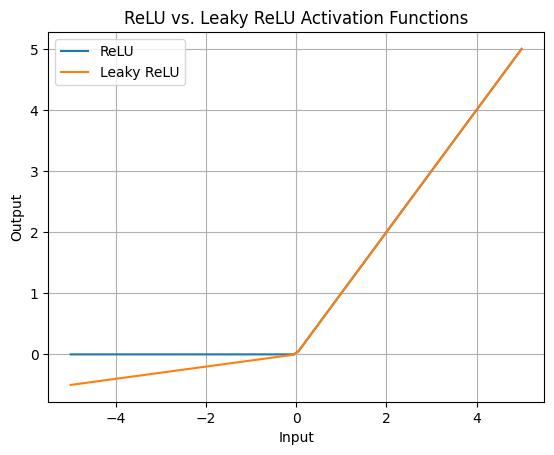

In [ ]:
# Comparing RELU vs LeakyRELU

# Define the range of input values
x = np.linspace(-5, 5, 100)

# Define the ReLU function
def relu(x):
  return np.maximum(0, x)

# Define the Leaky ReLU function
def leaky_relu(x, alpha=0.1):  # alpha is usually 0.01
  return np.maximum(alpha * x, x)

# Calculate the output values for both activation functions
y_relu = relu(x)
y_leaky_relu = leaky_relu(x)

# Plot the activation functions
plt.plot(x, y_relu, label='ReLU')
plt.plot(x, y_leaky_relu, label='Leaky ReLU')

# Add labels and title
plt.xlabel('Input')
plt.ylabel('Output')
plt.title('ReLU vs. Leaky ReLU Activation Functions')

# Add a legend
plt.legend()

# Display the plot
plt.grid(True)
plt.show()


In [ ]:
import torch
import torch.nn as nn

# Define some constants
PI = torch.from_numpy(np.asarray(np.pi))
EPS = 1.e-5

class Encoder(nn.Module):
    def __init__(self, encoder_net):
        super(Encoder, self).__init__()

        # The encoder network (e.g., MLP) that outputs concatenated [mu, log_var]
        self.encoder = encoder_net

    def reparameterization(self, mu, log_var):
        # Reparameterization trick:
        # Sample z ~ N(mu, sigma^2) using z = mu + sigma * epsilon,
        # where epsilon ~ N(0, I)
        std = torch.exp(0.5 * log_var)        # Convert log variance to standard deviation
        eps = torch.randn_like(std)           # Sample epsilon with the same shape as std (L=1)
        return mu + std * eps                 # Sample z

    def encode(self, x):
        # Forward input x through the encoder network to get mu and log_var
        h_e = self.encoder(x)                 # Output is of size 2M
        mu_e, log_var_e = torch.chunk(h_e, 2, dim=1)  # Split into two parts: mean and log variance
        return mu_e, log_var_e

    def sample(self, x=None, mu_e=None, log_var_e=None):
        # Return a sample from the approximate posterior
        # Can either compute mu/log_var from x or take them as input
        if (mu_e is None) and (log_var_e is None):
            mu_e, log_var_e = self.encode(x)
        else:
            if (mu_e is None) or (log_var_e is None):
                raise ValueError('mu and log_var can\'t be None!')
        z = self.reparameterization(mu_e, log_var_e)
        return z


### The Decoder

The decoder network is responsible for modeling the likelihood $ p_\theta(\mathbf{x} \mid \mathbf{z}) $, i.e., how the observed data $\mathbf{x}$ is generated from the latent variable $\mathbf{z}$. In our implementation, we assume that the data is composed of normalized images, so we now assume that the observed data is continuous and model it using a **Gaussian distribution**.

Thus, we define the likelihood as

$$
p_\theta(\mathbf{x} \mid \mathbf{z}) = \mathcal{N}\big(\mathbf{x} \;\big|\; \mu_\theta(\mathbf{z}), \; \mathrm{diag}(\sigma_\theta^2(\mathbf{z})) \big),
$$

where:

* $\mu_\theta(\mathbf{z})$ is the mean predicted by the decoder network,
* $\sigma_\theta^2(\mathbf{z})$ is the variance (or equivalently the log-variance), also predicted by the decoder.

The decoder network is therefore split into two branches, one producing $\mu_\theta(\mathbf{z})$ and another producing $\log \sigma_\theta^2(\mathbf{z})$.

The log-likelihood term is then

$$
\log p_\theta(\mathbf{x} \mid \mathbf{z}) = - \frac{1}{2}\Big[ D \log (2\pi) + \sum_{i=1}^D \log \sigma^2_{\theta,i}(\mathbf{z}) + \sum_{i=1}^D \frac{(x_i - \mu_{\theta,i}(\mathbf{z}))^2}{\sigma^2_{\theta,i}(\mathbf{z})} \Big].
$$

This formulation is the most flexible, since it allows the model to adaptively control the uncertainty of the reconstruction.


### **Practical case: fixed variance**

In practice, it is common to assume that the decoder variance is **constant and shared across all pixels**, i.e.,

$$
p_\theta(\mathbf{x} \mid \mathbf{z}) = \mathcal{N}\big(\mathbf{x} \;\big|\; \mu_\theta(\mathbf{z}), \; \sigma^2 I \big),
$$

with $\sigma^2$ being a fixed hyperparameter (e.g., set to 1).
The reasons are:

1. **Stability** – learning variances often leads to numerical instability, where the model collapses by driving variances toward zero or infinity.
2. **Simplicity** – in many real-world cases, the reconstruction error is dominated by the mean rather than the variance.
3. **Equivalence with MSE** – under fixed variance, maximizing the log-likelihood is equivalent (up to a constant scaling) to minimizing the **Mean Squared Error (MSE)**:

$$
\log p_\theta(\mathbf{x} \mid \mathbf{z}) \;\propto\; -\|\mathbf{x} - \mu_\theta(\mathbf{z})\|^2.
$$

Thus, the reconstruction term in the ELBO reduces to the familiar squared error loss.



In summary:

* **General case:** the decoder predicts both mean and variance, yielding a flexible probabilistic reconstruction.
* **Simplified case (most common):** the variance is fixed, and the decoder only predicts the mean. Training then becomes equivalent to minimizing an MSE reconstruction loss.

The architecture of the decoder is defined as follows:

```
z ∈ ℝ^M  
→ Linear(M, 256)  
→ LeakyReLU  
→ Linear(256, D)  
→ Identity (no activation) → μθ(z) ∈ ℝ^D  
```
### Some comments:

* The decoder must output **exactly $D$ values per image**, one per pixel, representing the mean of the Gaussian distribution for that pixel.
* Considering a mini-batch of $B$ samples, the decoder produces a tensor of shape $(B, D)$.
* The log-likelihood term for each data point is

$$
\log p_\theta(\mathbf{x} \mid \mathbf{z}) = -\frac{1}{2\sigma^2} \|\mathbf{x} - \mu_\theta(\mathbf{z})\|^2 + \text{const.},
$$

where the constant term does not depend on the parameters $\theta$. As a result, maximizing the likelihood is **equivalent to minimizing the Mean Squared Error (MSE)** between the input $\mathbf{x}$ and the reconstruction $\mu_\theta(\mathbf{z})$.

In [ ]:
import torch
import torch.nn as nn

EPS = 1e-8

class Decoder(nn.Module):
    def __init__(self, decoder_net, fixed_var=1.0):
        super(Decoder, self).__init__()
        self.decoder = decoder_net
        self.var = fixed_var  # Fixed variance

    def decode(self, z):
        # We only learn the mean of p(x|z), variance is fixed
        mu = self.decoder(z)
        return mu

    def sample(self, z):
        mu = self.decode(z)
        std = torch.sqrt(torch.tensor(self.var)).to(mu.device)
        eps = torch.randn_like(mu)
        return mu + eps * std

    def log_prob(self, x, z):
        mu = self.decode(z)
        # log N(x | mu, sigma^2 I) with fixed variance
        log_prob = -0.5 * ((x - mu) ** 2) / self.var - 0.5 * torch.log(2 * torch.pi * torch.tensor(self.var))
        # Note that first term is the MSE and second term is a constant depending on variance
        return log_prob.sum(dim=-1)


### Prior

In the VAE framework, the prior distribution over the latent variables is usually chosen to be a **standard multivariate Gaussian**:

$$
p(\mathbf{z}) = \mathcal{N}(\mathbf{z} \mid \mathbf{0}, \mathbf{I}),
$$

where $\mathbf{0}$ is a zero vector of dimension $M$ (the dimensionality of the latent space), and $\mathbf{I}$ is the identity matrix of size $M \times M$.

This class will be only use to generate samples, so it must be able to sample latent variables from the prior distribution:
    $$
    \mathbf{z} \sim p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I}).
    $$
  

In [ ]:
class Prior(nn.Module):
    def __init__(self, M):
        super(Prior, self).__init__()
        # M is the dimensionality of the latent space
        self.M = M

    def sample(self, batch_size):
        # Sample from a standard normal distribution (mean=0, std=1)
        z = torch.randn((batch_size, self.M))  # Shape: (batch_size, latent_dim)
        return z


### VAE Wrapper

Now we combine all the components into our **VAE model**. Let us consider a given dataset

$$
\mathcal{D} = \{ \mathbf{x}_n \}_{n=1}^N.
$$

As we know, the training objective of the VAE is to maximize the **Evidence Lower Bound (ELBO)**. In practice, since most deep learning libraries perform **minimization** by default, we minimize the **negative ELBO**, which can be expressed as:

$$
-\mathcal{L}(\mathcal{D}; \theta, \phi) = \sum_{n=1}^N \left\{
- \log p_\theta(\mathbf{x}_n \mid \mathbf{z}_{\phi,n})
+ \mathrm{KL}\!\left( q_\phi(\mathbf{z} \mid \mathbf{x}_n) \, \| \, p(\mathbf{z}) \right) \right\}.
$$

Here,

* The **reconstruction term** $- \log p_\theta(\mathbf{x}_n \mid \mathbf{z}_{\phi,n})$ depends on the likelihood model chosen for the decoder. For example, with a Gaussian likelihood and fixed variance, this reduces to the **Mean Squared Error (MSE)** between input and reconstruction.
  
* The **regularization term** is the KL divergence between the approximate posterior $q_\phi(\mathbf{z} \mid \mathbf{x})$ and the prior $p(\mathbf{z})$. For Gaussian posteriors, this term has a closed-form expression:

$$
\mathrm{KL}\!\left( q_\phi(\mathbf{z} \mid \mathbf{x}_n) \,\|\, p(\mathbf{z}) \right)
= \frac{1}{2} \sum_{m=1}^M \left( \sigma_{\phi,m}^2(\mathbf{x}_n) + \mu_{\phi,m}^2(\mathbf{x}_n) - 1 - \log \sigma_{\phi,m}^2(\mathbf{x}_n) \right).
$$

As discussed previously, $\mathbf{z}_{\phi,n}$ are samples generated by the encoder (using the reparameterization trick) to approximate the expectation in the reconstruction term.


This class will provide two main methods:

* The `forward` method computes the **negative ELBO** for a given batch of data by evaluating both the reconstruction loss (determined by the likelihood model of the decoder) and the KL divergence.
* The `sample` method generates new samples from the model by first drawing latent variables from the prior distribution and then decoding them using the decoder network.


In [ ]:
class VAE(nn.Module):
    def __init__(self, encoder_net, decoder_net, M=16):
        super(VAE, self).__init__()

        self.encoder = Encoder(encoder_net=encoder_net)
        self.decoder = Decoder(decoder_net=decoder_net)
        self.prior = Prior(M=M)

    def forward(self, x):
        # generate a latent variable, for each training sample, with the encoder
        mu_e, log_var_e = self.encoder.encode(x)
        z = self.encoder.sample(mu_e=mu_e, log_var_e=log_var_e)

        # ELBO
        RE = self.decoder.log_prob(x, z)
        KL = - 0.5 * torch.sum(torch.exp(log_var_e) + mu_e**2 - 1 - log_var_e, dim=1)
        return -(RE + KL).sum()


    def sample(self, batch_size=64):
        # Generate a latent variable with the prior
        z = self.prior.sample(batch_size=batch_size)
        return self.decoder.sample(z)

## Auxiliary functions: training, evaluation, plotting

In [ ]:
def evaluation(test_loader, model_best, epoch=None):
    # EVALUATION
    model_best.eval()
    loss = 0.
    N = 0.
    for indx_batch, test_batch in enumerate(test_loader):
        loss_t = model_best.forward(test_batch)
        loss = loss + loss_t.item()
        N = N + test_batch.shape[0]
    loss = loss / N

    if epoch is None:
        print(f'FINAL LOSS: nll={loss}')
    else:
        print(f'Epoch: {epoch}, val nll={loss}')

    return loss

def training(max_patience, num_epochs, model, optimizer, training_loader, val_loader, scheduler=None):
    nll_val = []
    best_nll = 1000
    patience = 0

    # Main loop
    for e in range(num_epochs):
        # TRAINING
        model.train()
        for indx_batch, batch in enumerate(training_loader):
            loss = model.forward(batch)

            optimizer.zero_grad()
            loss.backward(retain_graph=True)
            optimizer.step()

        # Step the scheduler after each epoch
        if scheduler is not None:
            scheduler.step()


        # Validation
        loss_val = evaluation(val_loader, model_best=model, epoch=e)
        nll_val.append(loss_val)  # save for plotting

        if e == 0:
            best_nll = loss_val
            best_model = model
        else:
            if loss_val < best_nll:
                best_nll = loss_val
                patience = 0
                best_model = model
            else:
                patience = patience + 1

        if patience > max_patience:
            break

    nll_val = np.asarray(nll_val)

    # Plot the curve
    plt.plot(np.arange(len(nll_val)), nll_val, linewidth='3')
    plt.xlabel('epochs')
    plt.ylabel('nll')
    plt.show()
    return nll_val, best_model


Some parameter definition

In [ ]:
D = D   # input dimension
M = 8  # number of latents
hidden_layer_neurons = 128  # the number of neurons in encoder and decoder nets

lr = 1e-3 # starting learning rate
num_epochs = 500 # max. number of epochs
max_patience = 20 # an early stopping is used, if training doesn't improve for longer than 20 epochs, it is stopped



In [ ]:
from pytorch_model_summary import summary

encoder = nn.Sequential(nn.Linear(D, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, 2 * M))

decoder = nn.Sequential(nn.Linear(M, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
                        nn.Linear(hidden_layer_neurons, D))

#prior = torch.distributions.MultivariateNormal(torch.zeros(M), torch.eye(M))
model = VAE(encoder_net=encoder, decoder_net=decoder, M=M)

# Print the summary
print("ENCODER:\n", summary(encoder, torch.zeros(1, D), show_input=False, show_hierarchical=False))
print("\nDECODER:\n", summary(decoder, torch.zeros(1, M), show_input=False, show_hierarchical=False))

ENCODER:
 -----------------------------------------------------------------------
      Layer (type)        Output Shape         Param #     Tr. Param #
          Linear-1            [1, 128]         100,480         100,480
       LeakyReLU-2            [1, 128]               0               0
          Linear-3            [1, 128]          16,512          16,512
       LeakyReLU-4            [1, 128]               0               0
          Linear-5             [1, 16]           2,064           2,064
Total params: 119,056
Trainable params: 119,056
Non-trainable params: 0
-----------------------------------------------------------------------

DECODER:
 -----------------------------------------------------------------------
      Layer (type)        Output Shape         Param #     Tr. Param #
          Linear-1            [1, 128]           1,152           1,152
       LeakyReLU-2            [1, 128]               0               0
          Linear-3            [1, 128]          16,5

In [ ]:
# OPTIMIZER
optimizer = torch.optim.Adamax([p for p in model.parameters() if p.requires_grad == True], lr=lr)

Epoch: 0, val nll=895.28247109375
Epoch: 1, val nll=870.5428052734375
Epoch: 2, val nll=861.4951239257813
Epoch: 3, val nll=856.128351953125
Epoch: 4, val nll=852.1207135742187
Epoch: 5, val nll=849.3117154296875
Epoch: 6, val nll=847.4261903320313
Epoch: 7, val nll=844.9752537109375
Epoch: 8, val nll=843.2587271484375
Epoch: 9, val nll=842.05897109375
Epoch: 10, val nll=840.5710287109375
Epoch: 11, val nll=839.6190521484375
Epoch: 12, val nll=838.6403224609375
Epoch: 13, val nll=837.8264392578125
Epoch: 14, val nll=836.896323828125
Epoch: 15, val nll=836.4108380859375
Epoch: 16, val nll=835.605607421875
Epoch: 17, val nll=834.9638822265625
Epoch: 18, val nll=834.6390876953125
Epoch: 19, val nll=833.9828258789063
Epoch: 20, val nll=833.3475880859374
Epoch: 21, val nll=833.4807504882813
Epoch: 22, val nll=832.4888586914062
Epoch: 23, val nll=832.27876875
Epoch: 24, val nll=831.7639793945312
Epoch: 25, val nll=831.5824768554687
Epoch: 26, val nll=831.2411920898437
Epoch: 27, val nll=830.

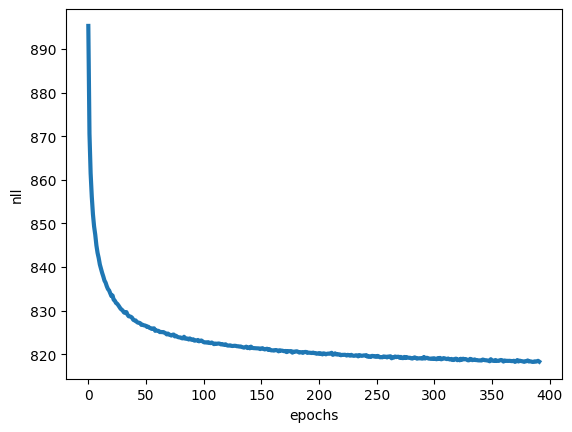

In [ ]:
# Training procedure
nll_val, best_model = training(max_patience=max_patience, num_epochs=num_epochs, model=model, optimizer=optimizer,
                       training_loader=training_loader, val_loader=val_loader)


In [ ]:
test_loss = evaluation(test_loader=test_loader, model_best = best_model)

FINAL LOSS: nll=818.2929109375


In [ ]:
def samples_generated(model_best):

    model_best.eval()
    num_x = 4
    num_y = 4
    x = model_best.sample(num_x * num_y)
    x = x.detach().numpy()

    fig, ax = plt.subplots(num_x, num_y)
    for i, ax in enumerate(ax.flatten()):
        plottable_image = np.reshape(x[i], (28, 28))
        ax.imshow(plottable_image, cmap='gray')
        ax.axis('off')


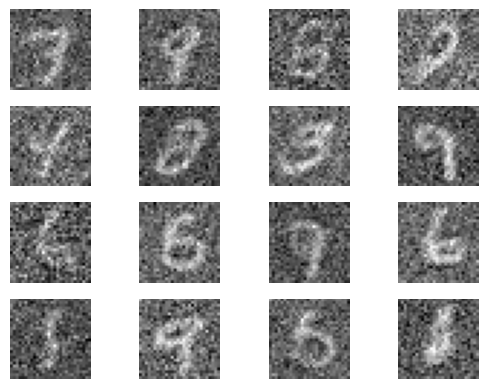

In [ ]:
samples_generated(best_model)

## Likelihood modeling in the VAE decoder: What loss function should I use?

In a **Variational Autoencoder (VAE)**, the objective function consists of two main components:

1. **Reconstruction term**:
   The expected log-likelihood of the data given the latent variable,

   $$
   \mathbb{E}_{q_\phi(z|x)} \left[ \log p_\theta(x|z) \right]
   $$

2. **Regularization term**:
   A Kullback–Leibler divergence between the approximate posterior and the prior,

   $$
   \mathrm{KL}(q_\phi(z|x) \, \| \, p(z))
   $$

The **reconstruction term depends directly on the likelihood model $p_\theta(x|z)$** assumed in the decoder. This likelihood determines the appropriate **reconstruction loss** and reflects the statistical assumptions about the nature of the data.

Below, we describe three common likelihood choices and the associated loss functions.


### 1. **Gaussian Likelihood**

* **Use when**: your data is continuous, and you assume Gaussian noise in the reconstructions.
* **Decoder output**: mean values of the predicted distribution, optionally with learned variance.

* **Assumption**:

  $$
  p(x|z) = \mathcal{N}(x; \mu(z), \sigma^2 I)
  $$
* **Reconstruction loss** (if variance $\sigma^2$ is constant):

  $$
  \mathcal{L}_\text{rec} = \frac{1}{2\sigma^2} \|x - \mu(z)\|^2 + \text{const}
  $$
* **Loss function**: **Mean Squared Error (MSE)** or **Negative Log-Likelihood** of a Gaussian.

When the variance is constant and not learned, minimizing the **MSE** is equivalent to maximizing the log-likelihood of a Gaussian decoder. This is the most common loss for continuous data (e.g., regression, autoencoding real-valued vectors).


### 2. **Categorical Likelihood**

* **Use when**: your data is discrete and each input sample corresponds to a class label or a one-hot vector (e.g., pixels intensities 1-256, words, tokens).
* **Decoder output**: a vector of class probabilities via `softmax`.

* **Assumption**:
  $$
  p(x|z) = \mathrm{Cat}(x; \text{softmax}(f_\theta(z)))
  $$
* **Reconstruction loss**:
  $$
  \mathcal{L}_\text{rec} = - \sum_{l} \mathbb{I}(\mathbf{x} = l) \log \theta_l
  $$

* **Loss function**: **Categorical cross-entropy** (a.k.a. `nn.CrossEntropyLoss` or `F.cross_entropy` in PyTorch).

This is the appropriate choice for tasks like word prediction, or when modeling pixel intensities as discrete values (e.g., using 256 classes for pixel values).

**Reminder:**
The **categorical distribution** is a discrete probability distribution that models the outcome of a random variable $\mathbf{x}$ which can take one of $L $ possible values (classes or categories), i.e., $\mathbf{x} \in \{0, 1, \ldots, L-1\}$.

This distribution is parameterized by a probability vector $\boldsymbol{\theta}(\mathbf{z}) \in \mathbb{R}^L $, where each component satisfies:

- $ \theta_l(\mathbf{z}) > 0$
- $\sum_{l=0}^{L-1} \theta_l(\mathbf{z}) = 1 $

Here, $\theta_l(\mathbf{z})$ represents the **probability** that $\mathbf{x} = l$. Then, the **probability mass function (pmf)** of the categorical distribution can be written as:

$$
p(\mathbf{x}|\mathbf{z}) = \prod_{l=1}^L \theta_l(\mathbf{z})^{\mathbb{I}(\mathbf{x} = l)}
$$

where $\mathbb{I}(\mathbf{x} = l) $ is the indicator function, which equals 1 if $\mathbf{x} = l$, and 0 otherwise.

Accordingly, the **log-probability** of a given observation $\mathbf{x}_i $ under the distribution parameterized by $ \boldsymbol{\theta}(\mathbf{z}_i) $ becomes:

$$
\log p_{\theta}(\mathbf{x}_i \mid \mathbf{z}_i) = \sum_{l=1}^L \mathbb{I}(\mathbf{x}_i = l) \log \theta_l(\mathbf{z}_i)
$$

This is exactly the **categorical cross-entropy loss**.

### 3. **Soft-Bernoulli Likelihood**

* **Use when**: your data is binary, or when your features (values to generate) are normalized in $[0, 1]$, and you interpret them as probabilities.
* **Decoder output**: pixel-wise probabilities via `sigmoid` -> $\theta$
* **Assumption**:

  $$
  p(x|z) = \prod_{i} \mathrm{Bern}(x_i; \theta_i), \quad \theta_i \in [0, 1]
  $$
* **Reconstruction loss**:

  $$
  \mathcal{L}_\text{rec} = - \sum_i \left[ x_i \log \theta_i + (1 - x_i) \log (1 - \theta_i) \right]
  $$

* **Loss function**: **Binary cross-entropy** (`F.binary_cross_entropy`).

This is commonly used when modeling images with grayscale or binary pixels, even if the pixel values are continuous in \[0,1]. It allows the model to treat each pixel as an independent probability.

**Reminder:** When $L = 2$, the categorical distribution reduces to a **Bernoulli distribution**. Taking into account that $\theta_i$ models the probability of $x_i$ is $1$, the log-likelihood becomes:

$$
\log p_\theta(\mathbf{x} \mid \mathbf{z}) = x \log \theta_i + (1-x) \log (1 - \theta_i).
$$

Thus, the reconstruction loss is:

$$
\mathcal{L}_\text{rec} = - \left[ x \log \theta_i + (1-x) \log (1 - \theta_i) \right],
$$

which is precisely the **Binary Cross-Entropy (BCE)** loss commonly used in practice.


## Summary Table

| Likelihood  | Data Type                 | Decoder Output        | Loss Function        | Typical Use Case              |
| ----------- | ------------------------- | --------------------- | -------------------- | ----------------------------- |
| Gaussian    | Continuous                | Real-valued output    | MSE or Gaussian NLL  | Regression, natural images    |
| Categorical | Discrete labels or tokens | Softmax logits        | Cross Entropy        | Discrete pixel intensities, word modeling |
| Bernoulli   | Binary or $[0,1]$ images  | Sigmoid probabilities | Binary Cross Entropy | Binary/grayscale images       |


## Implementation Tip
* Use `F.mse_loss(recon_x, x)` for Gaussian
* Use `F.cross_entropy(logits, labels)` for Categorical
* Use `F.binary_cross_entropy(recon_x, x)` for Bernoulli. If you're working with logits (i.e., pre-sigmoid outputs), use `F.binary_cross_entropy_with_logits` for numerical stability, but **only with binary targets (0 or 1)**.




## Modifying the VAE decoder

To adapt our VAE to the characteristics of the data, we replace the Gaussian likelihood in the decoder with a Bernoulli-based formulation. Specifically, we avoid any pixel normalization beyond the natural scaling of intensities to the interval $[0,1]$. In this setting, it is natural to interpret each pixel value as the parameter of an independent Bernoulli random variable. Concretely, the decoder outputs values in $[0,1]$ through a sigmoid activation, which directly define the probabilities of a soft-Bernoulli distribution over pixels.

In [ ]:
mnist_transforms_nonorm = transforms.Compose([
    transforms.ToTensor(),  # Original values are in [0,1]
    # No normalization!
])

train_dataset = MNIST(mode='train', transforms=mnist_transforms_nonorm)
val_dataset = MNIST(mode='val', transforms=mnist_transforms_nonorm)
test_dataset = MNIST(mode='val', transforms=mnist_transforms_nonorm)

batch_size = 64
training_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Epoch: 0, val nll=177.92505053710937
Epoch: 1, val nll=146.09217094726563
Epoch: 2, val nll=134.1908805419922
Epoch: 3, val nll=129.02327149658203
Epoch: 4, val nll=124.86442080078125
Epoch: 5, val nll=121.9126501953125
Epoch: 6, val nll=120.01476337890625
Epoch: 7, val nll=118.57443598632813
Epoch: 8, val nll=117.78508742675781
Epoch: 9, val nll=116.73545739746093
Epoch: 10, val nll=116.19890169677734
Epoch: 11, val nll=115.66172475585938
Epoch: 12, val nll=115.00900231933593
Epoch: 13, val nll=114.75617103271485
Epoch: 14, val nll=114.11306518554687
Epoch: 15, val nll=113.73385554199218
Epoch: 16, val nll=113.43657178955078
Epoch: 17, val nll=113.129458203125
Epoch: 18, val nll=112.77598779296875
Epoch: 19, val nll=112.61340504150391
Epoch: 20, val nll=112.14425705566406
Epoch: 21, val nll=112.02839038085938
Epoch: 22, val nll=111.85526730957031
Epoch: 23, val nll=111.54064013671875
Epoch: 24, val nll=111.37911552734376
Epoch: 25, val nll=111.28379252929687
Epoch: 26, val nll=111.171

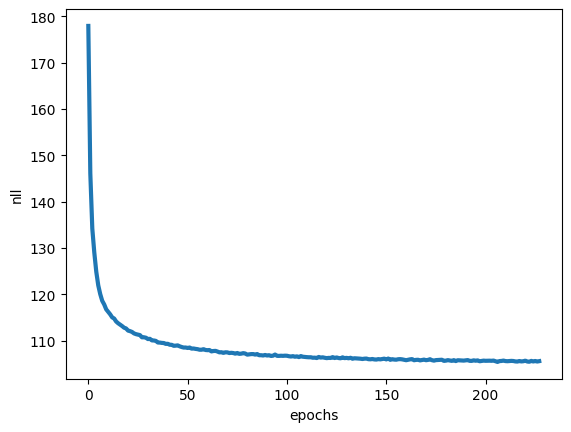

FINAL LOSS: nll=105.53244753417968
Test ELBO loss (Bernoulli): 105.53


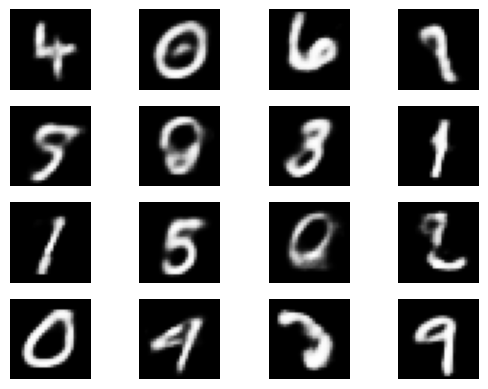

In [ ]:
# 2. Modify the Decoder with the soft-Bernoulli distribution (include a sigmoid in the output and compute log_prob with BCE)
import torch.nn.functional as F

class BernoulliDecoder(nn.Module):
    def __init__(self, decoder_net):
        super(BernoulliDecoder, self).__init__()
        self.decoder = decoder_net

    def decode(self, z):
        logits = self.decoder(z)
        probs = torch.sigmoid(logits)
        return probs

    def sample(self, z):
        probs = self.decode(z)
        return probs  # Return probabilities in [0,1]

    def log_prob(self, x, z):
        theta = self.decode(z)
        # BCE
        # Check x values are between 0 and 1
        if torch.any(x < 0) or torch.any(x > 1):
            raise ValueError('Input x must be in the range [0, 1] for Bernoulli log_prob computation.')
        log_prob = -F.binary_cross_entropy(theta, x, reduction='none').sum(dim=1)
        return log_prob

# 3. Redefine the VAE with the new decoder
class VAE_Bernoulli(nn.Module):
    def __init__(self, encoder_net, decoder_net, M=16):
        super(VAE_Bernoulli, self).__init__()
        self.encoder = Encoder(encoder_net=encoder_net)
        self.decoder = BernoulliDecoder(decoder_net=decoder_net)
        self.prior = Prior(M=M)

    def forward(self, x):
        mu_e, log_var_e = self.encoder.encode(x)
        z = self.encoder.sample(mu_e=mu_e, log_var_e=log_var_e)
        RE = self.decoder.log_prob(x, z)
        KL = -0.5 * torch.sum(torch.exp(log_var_e) + mu_e**2 - 1 - log_var_e, dim=1)
        return -(RE + KL).sum()

    def sample(self, batch_size=64):
        z = self.prior.sample(batch_size=batch_size)
        return self.decoder.sample(z)

# 4. Train the model
encoder_bern = nn.Sequential(
    nn.Linear(D, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, 2 * M)
)

decoder_bern = nn.Sequential(
    nn.Linear(M, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, hidden_layer_neurons), nn.LeakyReLU(),
    nn.Linear(hidden_layer_neurons, D)
)
vae_bern = VAE_Bernoulli(encoder_net=encoder_bern, decoder_net=decoder_bern, M=M)
optimizer_bern = torch.optim.Adamax([p for p in vae_bern.parameters() if p.requires_grad], lr=1e-3)

nll_val_bern, best_model_bern = training(
    max_patience=max_patience,
    num_epochs=num_epochs,
    model=vae_bern,
    optimizer=optimizer_bern,
    training_loader=training_loader,
    val_loader=val_loader
)

test_loss_bern = evaluation(test_loader=test_loader, model_best=best_model_bern)
print(f"Test ELBO loss (Bernoulli): {test_loss_bern:.2f}")

# 5. Generate sample images
def samples_generated_bern(model_best):
    model_best.eval()
    num_x = 4
    num_y = 4
    x = model_best.sample(num_x * num_y)
    x = x.detach().cpu().numpy()
    fig, ax = plt.subplots(num_x, num_y)
    for i, ax in enumerate(ax.flatten()):
        plottable_image = np.reshape(x[i], (28, 28))
        ax.imshow(plottable_image, cmap='gray')
        ax.axis('off')
    plt.show()

samples_generated_bern(best_model_bern)